# C.R.A.T.E.R — Transmit (rover → Mission Control over a lossy link)

**Input:** `telemetry_events.json` from the localization notebook (a built-in sample is used if the file is missing).
**Output:** `received_hazards.json`: what Mission Control actually knows after the link has dropped, corrupted, duplicated and reordered packets. This is the input of the dashboard.

What is built here:

| Piece | Problem it solves |
|---|---|
| Compact binary message (13 bytes) | Tiny bandwidth |
| Sequence number (1 byte, with wrap-around) | Duplicates, reordering, and detecting gaps |
| CRC-16 | Corrupted packets |
| Heartbeat (4 bytes, every second) | Exposes a lost *last* message |
| NACK + resend buffer | Lost packets |
| Repeat of important hazards | Extra survival for what matters most |

Everything runs in **virtual time**, so experiments are fast and reproducible (same seed = same result).

## 1. Setup and settings

In [1]:
import json, math, struct, binascii, heapq, os
from collections import Counter, OrderedDict
from dataclasses import dataclass, replace

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
EVENTS_PATH = "telemetry_events.json"      # output of the localization notebook

# The unreliable link (both directions use these numbers)
LINK = dict(
    loss=0.30,        # probability that a packet is lost
    corrupt=0.05,     # probability that one random bit is flipped
    dup=0.05,         # probability that the packet is delivered twice
    delay=0.30,       # base one-way delay (s)
    jitter=0.20,      # extra random delay (s): this causes reordering
    blackouts=(),     # e.g. ((1.0, 7.0),) = nothing gets through between t=1 s and t=7 s
)

@dataclass
class Proto:
    check_crc: bool = True
    nack: bool = True                       # receiver asks for missing packets, sender resends
    heartbeat: bool = True                  # sender announces its latest sequence number
    repeat_important: bool = True           # send important hazards twice
    important_classes: tuple = ("ice", "crater")   # <-- YOUR decision: what counts as important
    repeat_delay_s: float = 0.5             # when the second copy is sent
    hb_interval_s: float = 1.0
    nack_interval_s: float = 0.6            # how often the receiver repeats its request
    buffer_size: int = 64                   # how many sent messages the rover remembers (must be <= 128)
    settle_s: float = 30.0                  # time to keep simulating after the last event

PROTO = Proto()

## 2. Load the events from the localization step

In [3]:
SAMPLE_EVENTS = [
    (1,"rock",8,3,0.34,0.2,0.83,3),    (2,"rock",14,-3,0.92,0.2,0.84,3),  (3,"ice",11,-4,0.57,0.3,0.75,3),
    (2,"rock",14,-3,0.44,1.1,0.78,10), (4,"crater",21,1,1.75,1.2,0.82,3), (4,"crater",21,1,0.79,2.3,0.79,11),
    (4,"crater",21,1,0.39,3.7,0.74,25),(7,"crater",29,-4,1.77,4.6,0.88,3),(7,"crater",29,-4,0.85,5.3,0.82,10),
    (8,"rock",35,0,1.82,6.7,0.86,3),   (7,"crater",29,-4,0.41,6.9,0.78,25),(8,"rock",36,0,0.90,7.6,0.80,11),
    (8,"rock",36,0,0.44,9.2,0.79,25),
]
if os.path.exists(EVENTS_PATH):
    EVENTS = json.load(open(EVENTS_PATH))
    print(f"loaded {len(EVENTS)} events from {EVENTS_PATH}")
else:
    keys = ("hazard_id","cls","x_cell","y_cell","sigma_m","timestamp","confidence","n_obs")
    EVENTS = [dict(zip(keys, e)) for e in SAMPLE_EVENTS]
    print(f"{EVENTS_PATH} not found, using the built-in sample ({len(EVENTS)} events)")
EVENTS = sorted(EVENTS, key=lambda e: e["timestamp"])
pd.DataFrame(EVENTS).head()

loaded 13 events from telemetry_events.json


,hazard_id,cls,x_cell,y_cell,sigma_m,timestamp,confidence,n_obs
0,1,rock,8,3,0.34,0.2,0.83,3
1,2,rock,14,-3,0.92,0.2,0.84,3
2,3,ice,11,-4,0.57,0.3,0.75,3
3,2,rock,14,-3,0.44,1.1,0.78,10
4,4,crater,21,1,1.75,1.2,0.82,3


## 3. Message format

**DATA packet = 13 bytes**

| bytes | field | notes |
|---|---|---|
| 1 | flags | bits 7-6 packet type, 5-4 class (rock/crater/ice/other), 3 = important, 2 = this is a resend |
| 1 | seq | sequence number, wraps at 256 |
| 1 | hazard_id | |
| 2 + 2 | x_cell, y_cell | signed 16-bit |
| 1 | sigma | uncertainty in tenths of a metre (max 25.5 m) |
| 1 | confidence | 0 to 100 |
| 2 | time | mission time in tenths of a second (wraps after ~109 min) |
| 2 | CRC-16 | over everything above |

**HEARTBEAT = 4 bytes** (type, latest seq, CRC). **NACK = 4 + n bytes** (type, count, the n missing seqs, CRC).

In [4]:
CLASS_IDS = {"rock": 0, "crater": 1, "ice": 2}
CLASS_NAMES = {0: "rock", 1: "crater", 2: "ice", 3: "other"}
T_DATA, T_HB, T_NACK = 0, 1, 2
DATA_FMT = ">BBBhhBBH"
DATA_LEN = struct.calcsize(DATA_FMT)          # 11 bytes + 2 CRC = 13

def crc(b):          return binascii.crc_hqx(b, 0xFFFF)
def with_crc(body):  return body + struct.pack(">H", crc(body))
def clamp(v, lo, hi): return max(lo, min(hi, int(v)))

def pack_data(seq, ev, important=False, repeat=False):
    flags = (T_DATA << 6) | (CLASS_IDS.get(ev["cls"], 3) << 4) | (int(important) << 3) | (int(repeat) << 2)
    body = struct.pack(DATA_FMT, flags, seq & 0xFF, ev["hazard_id"] & 0xFF,
                       clamp(ev["x_cell"], -32768, 32767), clamp(ev["y_cell"], -32768, 32767),
                       clamp(round(ev["sigma_m"] * 10), 0, 255), clamp(round(ev["confidence"] * 100), 0, 100),
                       round(ev["timestamp"] * 10) & 0xFFFF)
    return with_crc(body)

def pack_heartbeat(last_seq):
    return with_crc(bytes([T_HB << 6, last_seq & 0xFF]))

def pack_nack(missing):
    missing = [m & 0xFF for m in missing][:8]
    return with_crc(bytes([T_NACK << 6, len(missing)] + missing))

def unpack(data, check_crc=True):
    """Returns a dict, or None if the packet is malformed / fails the CRC."""
    if len(data) < 4:
        return None
    body, rx = data[:-2], struct.unpack(">H", data[-2:])[0]
    if check_crc and crc(body) != rx:
        return None
    typ = body[0] >> 6
    if typ == T_DATA and len(body) == DATA_LEN:
        flags, seq, hid, x, y, s10, c, t10 = struct.unpack(DATA_FMT, body)
        return dict(type=T_DATA, seq=seq, hazard_id=hid, cls=CLASS_NAMES[(flags >> 4) & 3],
                    important=bool((flags >> 3) & 1), repeat=bool((flags >> 2) & 1),
                    x_cell=x, y_cell=y, sigma_m=s10 / 10, confidence=c / 100, t10=t10)
    if typ == T_HB and len(body) == 2:
        return dict(type=T_HB, seq=body[1])
    if typ == T_NACK and len(body) >= 2 and len(body) == 2 + body[1]:
        return dict(type=T_NACK, missing=list(body[2:]))
    return None

def unwrap(s, ref):
    """Turn an 8-bit sequence number into the full counter, picking the value closest to the latest one seen."""
    if ref < 0:
        return s
    base = ref - (ref % 256) + s
    return min((base - 256, base, base + 256), key=lambda c: abs(c - ref))

# --- tests ---
ev = EVENTS[0]
pkt = pack_data(5, ev, important=True)
print("DATA packet size:", len(pkt), "bytes | as JSON:", len(json.dumps(ev)), "bytes")
print("round trip:", unpack(pkt))
bad = bytearray(pkt); bad[4] ^= 0b00000100                     # flip one bit
print("after one flipped bit:", unpack(bytes(bad)))
assert unpack(pack_heartbeat(7))["seq"] == 7
assert unpack(pack_nack([3, 4]))["missing"] == [3, 4]
assert (unwrap(40, 300), unwrap(250, 300), unwrap(5, 300)) == (296, 250, 261)
print("all packet-format tests passed")

DATA packet size: 13 bytes | as JSON: 124 bytes
round trip: {'type': 0, 'seq': 5, 'hazard_id': 1, 'cls': 'rock', 'important': True, 'repeat': False, 'x_cell': 8, 'y_cell': 3, 'sigma_m': 0.3, 'confidence': 0.83, 't10': 2}
after one flipped bit: None
all packet-format tests passed


## 4. The lossy link (our radio emulator)

For every packet sent it randomly: **loses** it, **flips a bit**, **duplicates** it, and adds a **random delay** (so packets can overtake each other). During a **blackout** window nothing gets through.
There is one link per direction, and the return link (used for NACKs) is just as bad.

In [5]:
class LossyLink:
    def __init__(self, loss=0.3, corrupt=0.05, dup=0.05, delay=0.3, jitter=0.2, blackouts=(), rng=None):
        self.p = dict(loss=loss, corrupt=corrupt, dup=dup, delay=delay, jitter=jitter)
        self.blackouts, self.rng = blackouts, rng or np.random.default_rng(0)
        self.q, self.n = [], 0
        self.stats = Counter()

    def send(self, pkt, now):
        self.stats["packets"] += 1
        self.stats["bytes"] += len(pkt)
        if any(a <= now < b for a, b in self.blackouts):
            self.stats["lost_blackout"] += 1; return
        if self.rng.random() < self.p["loss"]:
            self.stats["lost"] += 1; return
        for _ in range(2 if self.rng.random() < self.p["dup"] else 1):
            data = pkt
            if self.rng.random() < self.p["corrupt"]:
                b = bytearray(pkt); k = int(self.rng.integers(len(b) * 8))
                b[k // 8] ^= 1 << (k % 8); data = bytes(b)
                self.stats["corrupted"] += 1
            t = now + self.p["delay"] + self.rng.random() * self.p["jitter"]
            self.n += 1
            heapq.heappush(self.q, (t, self.n, data))

    def deliver(self, now):
        out = []
        while self.q and self.q[0][0] <= now:
            out.append(heapq.heappop(self.q)[2])
        return out

## 5. Rover side (Sender) and Mission Control side (Receiver)

**Sender:** numbers each message, keeps the last `buffer_size` messages, sends important ones twice, sends a heartbeat every second, and resends whatever a NACK asks for.
**Receiver:** checks the CRC, ignores repeats, notices gaps in the sequence numbers (or a heartbeat that is ahead of what it has), asks again for the missing ones until they arrive, and keeps the **newest** update of every hazard (an old resend can never overwrite a newer position).

In [6]:
class Sender:
    def __init__(self, link, pc):
        self.link, self.pc = link, pc
        self.seq = 0
        self.buffer = OrderedDict()          # ext_seq -> (event, important)
        self.repeats = []                    # (due_time, ext_seq)
        self.last_hb = -1e9
        self.sent_time = {}
        self.stats = Counter()

    def _tx(self, ext, now, repeat):
        ev, imp = self.buffer[ext]
        self.link.send(pack_data(ext, ev, important=imp, repeat=repeat), now)

    def send_event(self, ev, now):
        pc, ext = self.pc, self.seq
        imp = pc.repeat_important and ev["cls"] in pc.important_classes
        self.buffer[ext] = (ev, imp)
        if len(self.buffer) > pc.buffer_size:
            self.buffer.popitem(last=False)
        self.sent_time[ext] = now
        self._tx(ext, now, repeat=False)
        self.stats["data"] += 1
        if imp:
            self.repeats.append((now + pc.repeat_delay_s, ext))
        self.seq += 1

    def tick(self, now):
        due = [r for r in self.repeats if r[0] <= now]
        self.repeats = [r for r in self.repeats if r[0] > now]
        for _, ext in due:
            if ext in self.buffer:
                self._tx(ext, now, repeat=True); self.stats["important_repeat"] += 1
        if self.pc.heartbeat and self.seq > 0 and now - self.last_hb >= self.pc.hb_interval_s:
            self.link.send(pack_heartbeat(self.seq - 1), now)
            self.last_hb = now; self.stats["heartbeat"] += 1

    def on_packet(self, data, now):
        m = unpack(data, self.pc.check_crc)
        if not m or m["type"] != T_NACK or not self.pc.nack:
            return
        by_mod = {k % 256: k for k in self.buffer}
        for s in m["missing"]:
            if s in by_mod:
                self._tx(by_mod[s], now, repeat=True); self.stats["resend"] += 1


class Receiver:
    def __init__(self, link_back, pc):
        self.link, self.pc = link_back, pc
        self.highest = -1
        self.got = set()
        self.first_rx = {}
        self.hazards = {}
        self.last_nack = -1e9
        self.stats = Counter()

    def on_packet(self, data, now):
        m = unpack(data, self.pc.check_crc)
        if m is None:
            self.stats["dropped_bad"] += 1; return
        if m["type"] == T_HB:
            self.highest = max(self.highest, unwrap(m["seq"], self.highest)); return
        if m["type"] != T_DATA:
            return
        ext = unwrap(m["seq"], self.highest)
        if ext in self.got:
            self.stats["duplicate_ignored"] += 1; return
        self.got.add(ext); self.first_rx[ext] = now
        self.highest = max(self.highest, ext)
        h = self.hazards.get(m["hazard_id"])
        if h is None or ext > h["ext_seq"]:                      # keep only the newest update
            self.hazards[m["hazard_id"]] = dict(
                hazard_id=m["hazard_id"], cls=m["cls"], x_cell=m["x_cell"], y_cell=m["y_cell"],
                sigma_m=m["sigma_m"], confidence=m["confidence"], obs_time_s=m["t10"] / 10,
                rx_time_s=round(now, 2), important=m["important"], ext_seq=ext)

    def tick(self, now):
        if not self.pc.nack:
            return
        missing = [s for s in range(self.highest + 1) if s not in self.got]
        if missing and now - self.last_nack >= self.pc.nack_interval_s:
            self.link.send(pack_nack(missing[:8]), now)
            self.last_nack = now; self.stats["nack_sent"] += 1

## 6. Simulation runner

Steps through virtual time (50 ms steps). At each step: the rover sends events that are due, both sides run their timers, and packets whose delay has passed are delivered.
It then compares what Mission Control knows with the **final** state of every hazard from the events file.

In [7]:
def simulate(events, link_cfg, pc, seed=0, dt=0.05):
    up = LossyLink(**link_cfg, rng=np.random.default_rng([seed, 1]))
    down = LossyLink(**link_cfg, rng=np.random.default_rng([seed, 2]))
    tx, rx = Sender(up, pc), Receiver(down, pc)
    evs = sorted(events, key=lambda e: e["timestamp"])
    n_steps = int((evs[-1]["timestamp"] + pc.settle_s) / dt)
    i = 0
    for k in range(n_steps + 1):
        t = k * dt
        while i < len(evs) and evs[i]["timestamp"] <= t:
            tx.send_event(evs[i], t); i += 1
        tx.tick(t); rx.tick(t)
        for d in up.deliver(t):   rx.on_packet(d, t)
        for d in down.deliver(t): tx.on_packet(d, t)

    truth = {e["hazard_id"]: e for e in evs}                      # final state of each hazard
    known = [h for h in truth if h in rx.hazards]
    exact = [h for h in known if (rx.hazards[h]["x_cell"], rx.hazards[h]["y_cell"], rx.hazards[h]["cls"]) ==
             (truth[h]["x_cell"], truth[h]["y_cell"], truth[h]["cls"] if truth[h]["cls"] in CLASS_IDS else "other")]
    delays = [rx.first_rx[e] - tx.sent_time[e] for e in rx.first_rx if e in tx.sent_time]
    metrics = dict(known_frac=len(known) / len(truth), exact_frac=len(exact) / len(truth),
                   pkt_delivery=len([e for e in rx.got if e in tx.sent_time]) / max(1, tx.seq),
                   bytes_up=up.stats["bytes"], bytes_down=down.stats["bytes"],
                   resend=tx.stats["resend"], dup_ignored=rx.stats["duplicate_ignored"],
                   bad_dropped=rx.stats["dropped_bad"], mean_delay=float(np.mean(delays)) if delays else np.nan)
    return metrics, tx, rx

## 7. One run with the settings above

In [8]:
m, tx, rx = simulate(EVENTS, LINK, PROTO, seed=1)
print(f"Mission Control knows {m['known_frac']:.0%} of the hazards, {m['exact_frac']:.0%} with the exact final cell")
print(f"messages sent: {tx.stats['data']} | packets delivered first time: {m['pkt_delivery']:.0%}")
print(f"resends triggered by NACK: {m['resend']} | important repeats: {tx.stats['important_repeat']}")
print(f"duplicates ignored: {m['dup_ignored']} | corrupted packets dropped by CRC: {m['bad_dropped']}")
print(f"bytes rover->base: {m['bytes_up']} | base->rover (NACKs): {m['bytes_down']} | mean delay: {m['mean_delay']:.2f} s")
pd.DataFrame(rx.hazards.values()).drop(columns="ext_seq").sort_values("hazard_id")

Mission Control knows 100% of the hazards, 100% with the exact final cell
messages sent: 13 | packets delivered first time: 100%
resends triggered by NACK: 3 | important repeats: 7
duplicates ignored: 8 | corrupted packets dropped by CRC: 1
bytes rover->base: 455 | base->rover (NACKs): 10 | mean delay: 0.56 s


,hazard_id,cls,x_cell,y_cell,sigma_m,confidence,obs_time_s,rx_time_s,important
0,1,rock,8,3,0.3,0.83,0.2,0.55,False
1,2,rock,14,-3,0.4,0.78,1.1,1.50,False
2,3,ice,11,-4,0.6,0.75,0.3,0.65,True
3,4,crater,21,1,0.4,0.74,3.7,4.20,True
4,7,crater,29,-4,0.4,0.78,6.9,7.40,True
5,8,rock,36,0,0.4,0.79,9.2,9.60,False


## 8. Experiment: which piece is worth its bytes?

Four versions of the protocol, each adding one piece, tested at loss rates from 0% to 70% (30 random runs each, averaged).
* **known**: share of hazards Mission Control has heard of at all.
* **exact**: share whose *latest* position is right (stale or corrupted data counts as wrong).
* **bytes**: total uplink bytes (the cost).

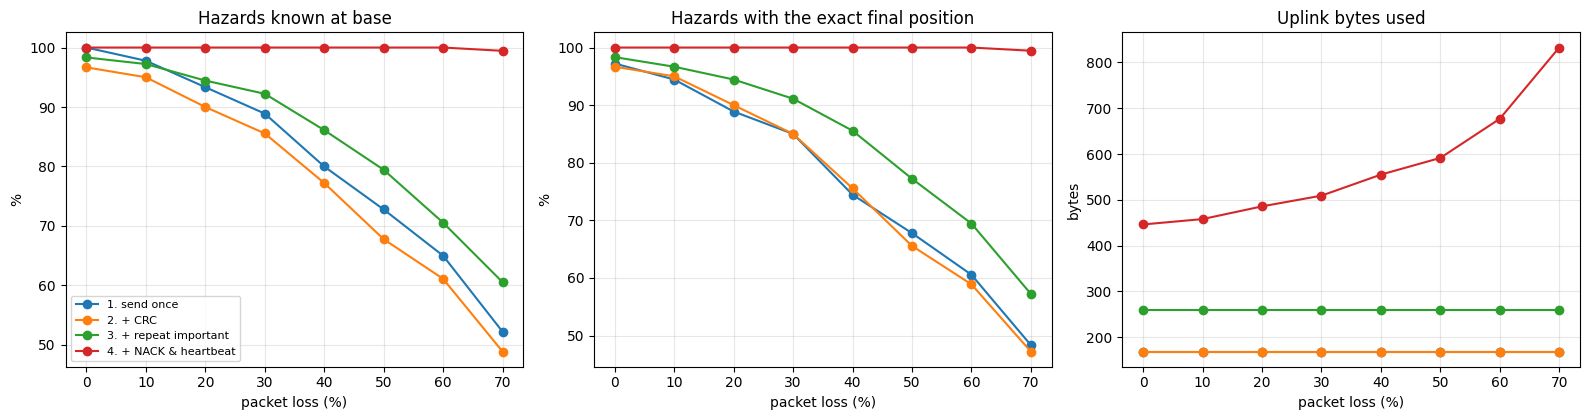

,variant,loss,known_frac,exact_frac,bytes_up,bytes_down,mean_delay
3,1. send once,0.3,0.89,0.85,169.00,0.00,0.42
5,1. send once,0.5,0.73,0.68,169.00,0.00,0.42
11,2. + CRC,0.3,0.86,0.85,169.00,0.00,0.42
13,2. + CRC,0.5,0.68,0.66,169.00,0.00,0.42
19,3. + repeat important,0.3,0.92,0.91,260.00,0.00,0.50
21,3. + repeat important,0.5,0.79,0.77,260.00,0.00,0.55
27,4. + NACK & heartbeat,0.3,1.00,1.00,509.17,42.60,0.96
29,4. + NACK & heartbeat,0.5,1.00,1.00,591.50,90.37,1.96


In [9]:
VARIANTS = {
    "1. send once":              replace(PROTO, check_crc=False, nack=False, heartbeat=False, repeat_important=False),
    "2. + CRC":                  replace(PROTO, nack=False, heartbeat=False, repeat_important=False),
    "3. + repeat important":     replace(PROTO, nack=False, heartbeat=False),
    "4. + NACK & heartbeat":     PROTO,
}
LOSSES = [0, .1, .2, .3, .4, .5, .6, .7]
N_SEEDS = 30

rows = []
for name, pc in VARIANTS.items():
    for L in LOSSES:
        for s in range(N_SEEDS):
            m, _, _ = simulate(EVENTS, dict(LINK, loss=L), pc, seed=s)
            rows.append(dict(variant=name, loss=L, **m))
R = pd.DataFrame(rows).groupby(["variant", "loss"]).mean(numeric_only=True).reset_index()

fig, ax = plt.subplots(1, 3, figsize=(16, 4.3))
for name in VARIANTS:
    d = R[R.variant == name]
    ax[0].plot(d.loss * 100, d.known_frac * 100, marker="o", label=name)
    ax[1].plot(d.loss * 100, d.exact_frac * 100, marker="o", label=name)
    ax[2].plot(d.loss * 100, d.bytes_up, marker="o", label=name)
for a, t, y in zip(ax, ["Hazards known at base", "Hazards with the exact final position", "Uplink bytes used"],
                   ["%", "%", "bytes"]):
    a.set_title(t); a.set_xlabel("packet loss (%)"); a.set_ylabel(y); a.grid(alpha=.3)
ax[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

R[R.loss.isin([0.3, 0.5])][["variant", "loss", "known_frac", "exact_frac", "bytes_up", "bytes_down", "mean_delay"]].round(2)

## 9. Blackout test

The link is completely dead from t = 1 s to t = 7 s (as inside a crater), on top of 30% loss. We compare "send once" with the full protocol and print when each message first reached Mission Control.

In [10]:
BLACK = dict(LINK, blackouts=((1.0, 7.0),))
for name in ["1. send once", "4. + NACK & heartbeat"]:
    m, tx, rx = simulate(EVENTS, BLACK, VARIANTS[name], seed=3)
    print(f"{name:26s} -> hazards known: {m['known_frac']:.0%}, exact: {m['exact_frac']:.0%}")
    if name.startswith("4"):
        full_tx, full_rx = tx, rx

tl = pd.DataFrame([dict(seq=e, hazard=full_tx.buffer[e][0]["hazard_id"], sent_at=full_tx.sent_time[e],
                        arrived_at=round(full_rx.first_rx[e], 2) if e in full_rx.first_rx else None)
                   for e in sorted(full_tx.buffer)])
tl["delay_s"] = (tl.arrived_at - tl.sent_at).round(2)
tl

1. send once               -> hazards known: 50%, exact: 50%
4. + NACK & heartbeat      -> hazards known: 100%, exact: 100%


,seq,hazard,sent_at,arrived_at,delay_s
0,0,1,0.2,8.25,8.05
1,1,2,0.2,0.65,0.45
2,2,3,0.3,0.70,0.40
3,3,2,1.1,14.60,13.50
4,4,4,1.2,10.30,9.10
5,5,4,2.3,10.30,8.00
6,6,4,3.7,13.50,9.80
7,7,7,4.6,10.45,5.85
8,8,7,5.3,12.75,7.45
9,9,8,6.7,12.90,6.20


## 10. Export for the dashboard

`received_hazards.json` is what Mission Control knows at the end of the run (full protocol, 30% loss).
For each hazard the dashboard gets the position cell, `sigma_m` (uncertainty), `obs_time_s` (when it was observed) and `rx_time_s` (when the message arrived). **Data age = now − obs_time_s.**

In [11]:
m, tx, rx = simulate(EVENTS, LINK, PROTO, seed=1)
out = [{k: v for k, v in h.items() if k != "ext_seq"} for h in sorted(rx.hazards.values(), key=lambda h: h["hazard_id"])]
with open("received_hazards.json", "w") as fh:
    json.dump(out, fh, indent=2)
print(f"wrote {len(out)} hazards to received_hazards.json")

wrote 6 hazards to received_hazards.json


## 11. Hand-off and things to decide

* **Time field:** it holds mission-relative seconds. If the dashboard uses wall-clock time, agree on one clock first.
* **"Important" rule:** currently `ice` and `crater`. Change `important_classes` (or write a rule based on confidence or distance) and defend it.
* **Class "other":** any class not in `CLASS_IDS` is sent as `other` (2 bits only). Add classes in `CLASS_IDS` and widen the field if needed.
* **Limits of this design:**
  - `hazard_id` is 8 bits (0–255). Fine for the demo; document if you ever expect more.
  - Timestamp is stored as tenths of a second in a 16-bit field (~1.8 h of mission time before wrap).
  - The sender never frees its buffer on ACK, so a gap larger than `buffer_size` messages cannot be repaired. Sequence numbers wrap safely as long as fewer than 128 messages are missing at once.
* **Next:** a script that runs detection → localization → transport → dashboard in one go (the 15% integration score).
